In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import pytesseract
from IPython.display import display
from PIL import Image

from doc_verify.config import DATA_DIR
from doc_verify.tobacco import load_tobacco, to_200_dpi
from sad_syn.analysis import (ablate_leave_one_out, ablate_one_at_a_time, compare_confidence,
                              label_gap_tests, ocr_accuracy, strength_summary)
from sad_syn.degrade import degrade
from sad_syn.generate import make_clean_offer, make_inconsistent_offer, make_letters, rule_test, set_seed
from sad_syn.ocr import check_ocr, page_confidences
from sad_syn.pipeline import DEGRADE_SEED, run_ocr, swapped_seeds
from sad_syn.render import render_offer, template_01

set_seed(42)

samples_dir = DATA_DIR / "samples"
samples_dir.mkdir(parents=True, exist_ok=True)

In [2]:
counts = rule_test(1000)
for kind, n in counts.items():
    print(f"{kind}: {n}/1000")

clean: 1000/1000
altered_date: 1000/1000
altered_amount: 1000/1000
institution_mismatch: 1000/1000
total_mismatch: 1000/1000


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/clean_letter.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/altered_amount_letter.png


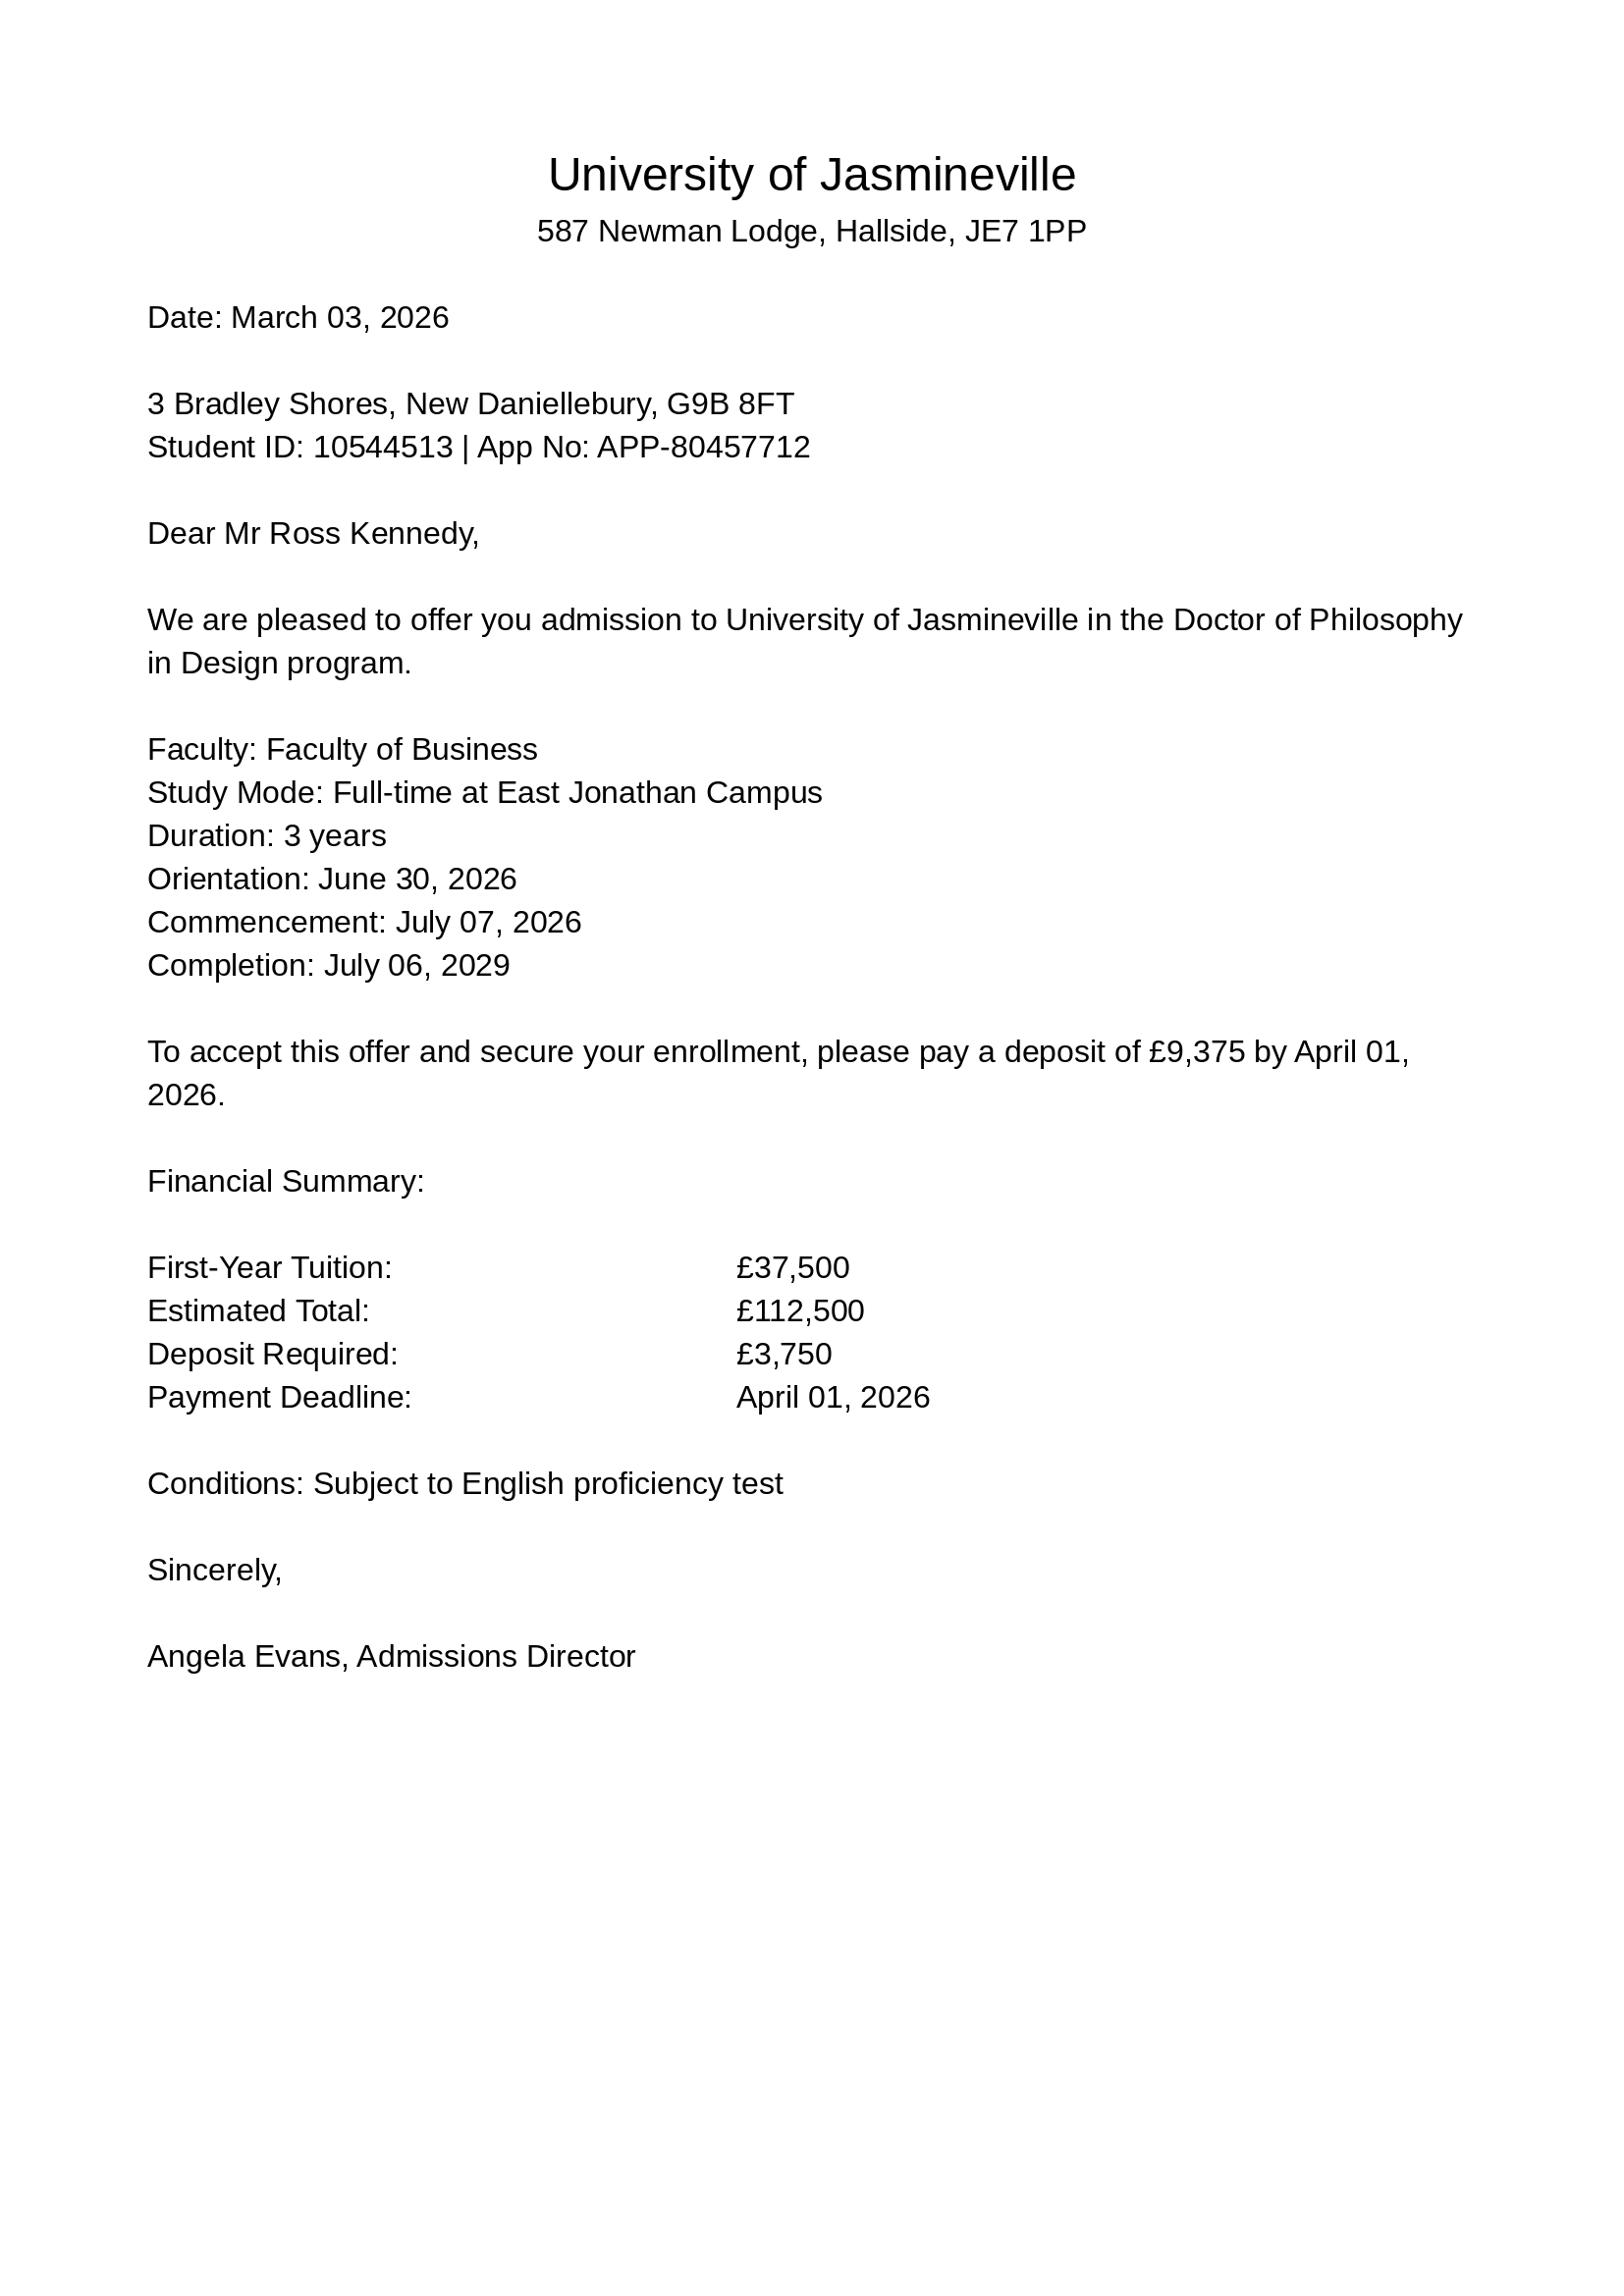

In [3]:
clean_offer = make_clean_offer()
altered_offer = make_inconsistent_offer("altered_amount")

clean_path = samples_dir / "clean_letter.png"
altered_path = samples_dir / "altered_amount_letter.png"

render_offer(clean_offer, template_01, clean_path)
render_offer(altered_offer, template_01, altered_path)

In [4]:
clean_text = pytesseract.image_to_string(Image.open(clean_path))
altered_text = pytesseract.image_to_string(Image.open(altered_path))

print(clean_text)
print("=" * 80)
print(altered_text)

Long University
Studio 38y, Beth Trail, North Reeceborough, G29 2UQ

Date: February 03, 2026

895 Keith Ports, Edwardsmouth, S64 7BJ
Student ID: 41965725 | App No: APP-14709303

Dear Jesse Martin,

We are pleased to offer you admission to Long University in the Bachelor of Computer Science
program.

Faculty: Faculty of Computing

Study Mode: Full-time at New Donald Campus
Duration: 3 years

Orientation: April 17, 2026

Commencement: April 24, 2026

Completion: April 23, 2029

To accept this offer and secure your enrollment, please pay a deposit of £2,300 by February 17,
2026.

Financial Summary:

First-Year Tuition: £23,000
Estimated Total: £69,000

Deposit Required: £2,300

Payment Deadline: February 17, 2026

Conditions: Subject to final academic transcripts
Sincerely,

Mrs Shirley Sheppard, Admissions Director

University of Jasmineville
587 Newman Lodge, Hallside, JE7 1PP

Date: March 03, 2026

3 Bradley Shores, New Daniellebury, G9B 8FT
Student ID: 10544513 | App No: APP-80457712


In [5]:
print("clean missing:", check_ocr(clean_offer, clean_text))
print("altered missing:", check_ocr(altered_offer, altered_text))

clean missing: {}
altered missing: {}


In [6]:
STRENGTHS = [0, 0.25, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 1]

set_seed(42)
offers = make_letters(100)
sweep = run_ocr(offers, template_01, STRENGTHS)

for strength in STRENGTHS:
    degrade(render_offer(offers[0], template_01), strength, DEGRADE_SEED).save(samples_dir / f"degrade_{strength:.2f}.png")

strength_summary(sweep)

,copies_read,copies_total,altered_value_ocr_ok,ocr_accuracy
strength,,,,
0.00,1200,1200,1.0,1.000000
0.25,1186,1200,1.0,0.988333
0.50,1183,1200,0.98,0.985833
0.55,1183,1200,0.98,0.985833
0.60,1168,1200,0.98,0.973333
0.65,1171,1200,0.98,0.975833
0.70,1171,1200,0.96,0.975833
0.75,1150,1200,0.94,0.958333
1.00,1076,1200,0.84,0.896667


In [7]:
set_seed(7)
gap_offers = make_letters(400)
gap = run_ocr(gap_offers, template_01, [0.5, 0.75])

ocr_accuracy(gap, ['strength', 'label']).unstack()

label,altered,clean
strength,,
0.50,0.98125,0.983750
0.75,0.94125,0.947083


In [8]:
label_gap_tests(gap)

,clean,altered,letters_per_group,z_test_p (copies as units),welch_t_p (letters as units)
strength,,,,,
0.50,0.983750,0.98125,200,0.50896,0.509735
0.75,0.947083,0.94125,200,0.37880,0.463366


In [9]:
gap_swapped = run_ocr(gap_offers, template_01, [0.75], seeds=swapped_seeds(len(gap_offers)))

pd.DataFrame({
    'original seeds': ocr_accuracy(gap[gap['strength'] == 0.75], 'label'),
    'swapped seeds': ocr_accuracy(gap_swapped, 'label'),
})

,original seeds,swapped seeds
label,,
altered,0.941250,0.947917
clean,0.947083,0.952083


In [10]:
ablate_one_at_a_time(offers, template_01, 0.75)

all effects        0.958333
rotation only      1.000000
blur only          1.000000
resolution only    1.000000
noise only         1.000000
stroke only        1.000000
threshold only     1.000000
specks only        0.987500
Name: ocr_accuracy, dtype: float64

In [11]:
ablate_leave_one_out(offers, template_01, 0.75)

all effects           0.958333
without rotation      0.965000
without blur          0.957500
without resolution    0.984167
without noise         0.952500
without stroke        0.964167
without threshold     0.972500
without specks        0.974167
Name: ocr_accuracy, dtype: float64

In [12]:
tobacco_letters = load_tobacco('Letter')
tobacco_conf = pd.Series(page_confidences(to_200_dpi(ex['image']) for ex in tobacco_letters), name='tobacco')

print(f"{len(tobacco_conf)} Tobacco letters, {tobacco_conf.isna().sum()} with no text found")
tobacco_conf.describe()

567 Tobacco letters, 0 with no text found


count    567.000000
mean      88.250195
std        6.092167
min       45.342593
25%       85.717763
50%       90.333333
75%       92.347945
max       95.345291
Name: tobacco, dtype: float64

In [13]:
compare_confidence(sweep, tobacco_conf, 'tobacco').round(3)

,no_text,q10,q25,q50,q75,q90,ks_vs_reference
tobacco,0.0,80.833,85.718,90.333,92.348,93.566,0.000
sad-syn 0.0,0.0,95.115,95.189,95.288,95.364,95.440,0.979
sad-syn 0.25,0.0,92.320,93.331,93.957,94.689,95.093,0.673
sad-syn 0.5,0.0,90.400,91.653,92.834,93.685,94.319,0.445
sad-syn 0.55,0.0,90.115,91.825,92.992,93.740,94.245,0.454
sad-syn 0.6,0.0,90.017,91.022,92.463,93.475,94.298,0.397
sad-syn 0.65,0.0,88.723,90.647,92.153,93.139,93.925,0.320
sad-syn 0.7,0.0,89.114,90.063,91.477,92.795,93.646,0.306
sad-syn 0.75,0.0,88.420,89.510,91.175,92.738,93.846,0.276
sad-syn 1.0,0.0,81.833,86.144,88.966,91.143,92.542,0.189


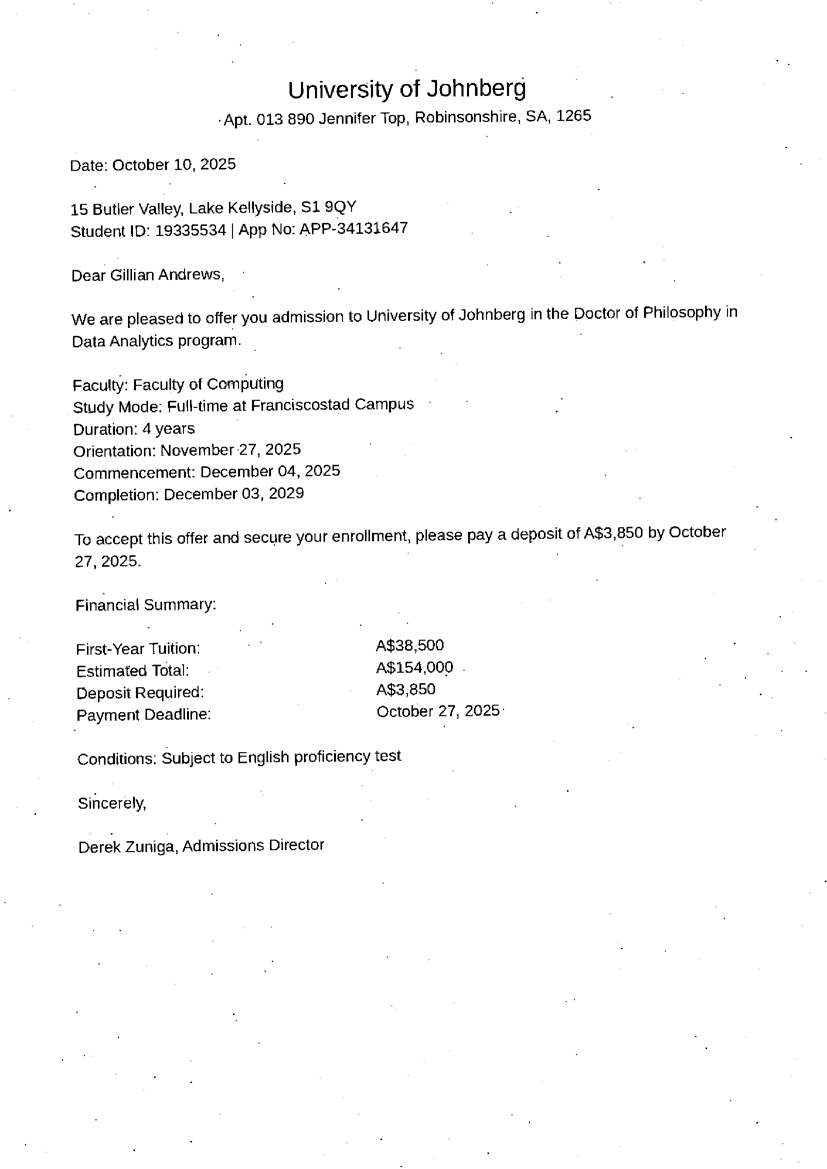

In [14]:
example = Image.open(samples_dir / "degrade_0.50.png")
display(example.resize((example.width // 2, example.height // 2)))